In [1]:
from pathlib import Path
import zipfile
import pandas as pd

# ---- 1. Create the project structure ----
project = Path.home() / "clinical-readmission-risk"
for sub in ["data/raw", "data/processed", "models", "notebooks", "src", "results"]:
    (project / sub).mkdir(parents=True, exist_ok=True)
print("Project created at:", project)
print("Subfolders:", [p.name for p in project.iterdir() if p.is_dir()])

# ---- 2. Find the DHS ZIP files anywhere under the user's home ----
home = Path.home()
targets = ["BDKR81DT.ZIP", "BDHR81DT.ZIP"]
found = {}

for name in targets:
    hits = list(home.rglob(name))
    # also try lowercase variant in case of case differences
    if not hits:
        hits = list(home.rglob(name.lower()))
    found[name] = hits
    if hits:
        for h in hits:
            print(f"FOUND {name}: {h}  ({h.stat().st_size // 1024} KB)")
    else:
        print(f"NOT FOUND: {name}")

# ---- 3. Extract whichever files were found ----
raw = project / "data" / "raw"
for name, hits in found.items():
    if not hits:
        continue
    zip_path = hits[0]
    print(f"\nExtracting {zip_path.name} ...")
    with zipfile.ZipFile(zip_path, "r") as z:
        for n in z.namelist():
            print("   inside zip:", n)
        z.extractall(raw)

print("\nContents of data/raw:")
for p in sorted(raw.iterdir()):
    print(f"   {p.name}  ({p.stat().st_size // 1024} KB)")

Project created at: C:\Users\Lenovo\clinical-readmission-risk
Subfolders: ['data', 'models', 'notebooks', 'results', 'src']
FOUND BDKR81DT.ZIP: C:\Users\Lenovo\Downloads\BDKR81DT.ZIP  (2383 KB)
FOUND BDHR81DT.ZIP: C:\Users\Lenovo\Downloads\BDHR81DT.ZIP  (8938 KB)

Extracting BDKR81DT.ZIP ...
   inside zip: BDKR81FL.FRQ
   inside zip: BDKR81FL.FRW
   inside zip: BDKR81FL.MAP
   inside zip: BDKR81FL.DTA
   inside zip: BDKR81FL.DO
   inside zip: BDKR81FL.DCT

Extracting BDHR81DT.ZIP ...
   inside zip: BDHR81FL.FRQ
   inside zip: BDHR81FL.FRW
   inside zip: BDHR81FL.MAP
   inside zip: BDHR81FL.DTA
   inside zip: BDHR81FL.DO
   inside zip: BDHR81FL.DCT

Contents of data/raw:
   BDHR81FL.DCT  (146 KB)
   BDHR81FL.DO  (367 KB)
   BDHR81FL.DTA  (134569 KB)
   BDHR81FL.FRQ  (6364 KB)
   BDHR81FL.FRW  (6364 KB)
   BDHR81FL.MAP  (157 KB)
   BDKR81FL.DCT  (48 KB)
   BDKR81FL.DO  (227 KB)
   BDKR81FL.DTA  (11875 KB)
   BDKR81FL.FRQ  (3487 KB)
   BDKR81FL.FRW  (3487 KB)
   BDKR81FL.MAP  (377 KB)


In [2]:
from pathlib import Path
import pandas as pd

raw = Path.home() / "clinical-readmission-risk" / "data" / "raw"

# ---- Load KR (Kids Recode) ----
kr = pd.read_stata(raw / "BDKR81FL.DTA", convert_categoricals=False)

print("=" * 50)
print("KR (Children's Recode)")
print("=" * 50)
print("Shape (rows, cols):", kr.shape)
print("Unique clusters (v001):", kr["v001"].nunique())

print("\nAnthropometric columns:", [c for c in kr.columns if c.startswith("hw7")])

print("\nKey variables present:")
for v in ["v001", "v002", "v005", "v025", "v190", "v106", "v445", "m14", "v008", "b3", "b19"]:
    print(f"   {v}: {'yes' if v in kr.columns else 'NO'}")

print("\nhw70 (height-for-age z-score):")
print(kr["hw70"].describe())
print("\n  Missing:", kr["hw70"].isna().sum())
print("  Special codes 9996-9999:", kr["hw70"].isin([9996, 9997, 9998, 9999]).sum())
print("  Zero values:", (kr["hw70"] == 0).sum())

print("\nhw71 (weight-for-age z-score):")
print("  Missing:", kr["hw71"].isna().sum())
print("  Special codes 9996-9999:", kr["hw71"].isin([9996, 9997, 9998, 9999]).sum())

print("\nhw72 (weight-for-height z-score):")
print("  Missing:", kr["hw72"].isna().sum())
print("  Special codes 9996-9999:", kr["hw72"].isin([9996, 9997, 9998, 9999]).sum())

# ---- Stunting prevalence (unweighted and weighted) ----
valid = ~kr["hw70"].isin([9996, 9997, 9998, 9999]) & kr["hw70"].notna()
stunted = (kr.loc[valid, "hw70"] < -200).astype(int)

unweighted_prev = stunted.mean()
weights = kr.loc[valid, "v005"] / 1_000_000
weighted_prev = (stunted * weights).sum() / weights.sum()

print("\n" + "=" * 50)
print("STUNTING PREVALENCE (children with valid hw70)")
print("=" * 50)
print(f"  N with valid hw70: {valid.sum()}")
print(f"  Unweighted prevalence: {unweighted_prev:.3f} ({unweighted_prev*100:.1f}%)")
print(f"  Weighted prevalence:   {weighted_prev:.3f} ({weighted_prev*100:.1f}%)")
print(f"  (Official BDHS-2022 report: ~24%)")

print("\n" + "=" * 50)
print("HR (Household Recode)")
print("=" * 50)
hr = pd.read_stata(raw / "BDHR81FL.DTA", convert_categoricals=False)
print("Shape:", hr.shape)
print("Cluster var (hv001) present:", "hv001" in hr.columns)
print("Water source (hv201) present:", "hv201" in hr.columns)
print("Toilet type (hv205) present:", "hv205" in hr.columns)
print("Wealth quintile (hv270) present:", "hv270" in hr.columns)

KR (Children's Recode)
Shape (rows, cols): (8784, 1238)
Unique clusters (v001): 674

Anthropometric columns: ['hw70', 'hw71', 'hw72', 'hw73']

Key variables present:
   v001: yes
   v002: yes
   v005: yes
   v025: yes
   v190: yes
   v106: yes
   v445: yes
   m14: yes
   v008: yes
   b3: yes
   b19: yes

hw70 (height-for-age z-score):
count    4118.000000
mean      -83.978630
std       581.389224
min      -581.000000
25%      -195.000000
50%      -119.000000
75%       -38.000000
max      9998.000000
Name: hw70, dtype: float64

  Missing: 4666
  Special codes 9996-9999: 13
  Zero values: 4

hw71 (weight-for-age z-score):
  Missing: 4624
  Special codes 9996-9999: 2

hw72 (weight-for-height z-score):
  Missing: 4661
  Special codes 9996-9999: 19

STUNTING PREVALENCE (children with valid hw70)
  N with valid hw70: 4105
  Unweighted prevalence: 0.235 (23.5%)
  Weighted prevalence:   0.232 (23.2%)
  (Official BDHS-2022 report: ~24%)

HR (Household Recode)
Shape: (30018, 3751)
Cluster var (h

In [ ]:
import numpy as np

# Recreate the valid mask
invalid = kr["hw70"].isin([9996, 9997, 9998, 9999])
valid = ~invalid & kr["hw70"].notna()
missing = ~invalid & kr["hw70"].isna()

print("Valid hw70:", valid.sum())
print("Missing hw70 (NaN):", missing.sum())
print("Special codes:", invalid.sum())

# Child age in months (b19) — available in KR
print("\nAge distribution of children WITH valid hw70:")
print(kr.loc[valid, "b19"].describe().round(1))

print("\nAge distribution of children WITHOUT valid hw70:")
print(kr.loc[missing, "b19"].describe().round(1))

# Missingness by residence (v025: 1=urban, 2=rural)
print("\nMissingness rate by residence:")
print(kr.groupby("v025")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# Missingness by wealth quintile (v190: 1=poorest ... 5=richest)
print("\nMissingness rate by wealth quintile:")
print(kr.groupby("v190")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# Missingness by region (v024)
print("\nMissingness rate by region:")
print(kr.groupby("v024")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# How many children are older than 59 months (outside anthropometry window)?
print("\nChildren with b19 >= 60 months:", (kr["b19"] >= 60).sum())
print("  of which missing hw70:", ((kr["b19"] >= 60) & missing).sum())
print("  of which valid hw70:", ((kr["b19"] >= 60) & valid).sum())

In [3]:
import numpy as np

# Recreate the valid mask
invalid = kr["hw70"].isin([9996, 9997, 9998, 9999])
valid = ~invalid & kr["hw70"].notna()
missing = ~invalid & kr["hw70"].isna()

print("Valid hw70:", valid.sum())
print("Missing hw70 (NaN):", missing.sum())
print("Special codes:", invalid.sum())

# Child age in months (b19) — available in KR
print("\nAge distribution of children WITH valid hw70:")
print(kr.loc[valid, "b19"].describe().round(1))

print("\nAge distribution of children WITHOUT valid hw70:")
print(kr.loc[missing, "b19"].describe().round(1))

# Missingness by residence (v025: 1=urban, 2=rural)
print("\nMissingness rate by residence:")
print(kr.groupby("v025")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# Missingness by wealth quintile (v190: 1=poorest ... 5=richest)
print("\nMissingness rate by wealth quintile:")
print(kr.groupby("v190")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# Missingness by region (v024)
print("\nMissingness rate by region:")
print(kr.groupby("v024")["hw70"].apply(lambda s: s.isna().mean()).round(3))

# How many children are older than 59 months (outside anthropometry window)?
print("\nChildren with b19 >= 60 months:", (kr["b19"] >= 60).sum())
print("  of which missing hw70:", ((kr["b19"] >= 60) & missing).sum())
print("  of which valid hw70:", ((kr["b19"] >= 60) & valid).sum())

Valid hw70: 4105
Missing hw70 (NaN): 4666
Special codes: 13

Age distribution of children WITH valid hw70:
count    4105.0
mean       29.1
std        17.6
min         0.0
25%        13.0
50%        29.0
75%        45.0
max        59.0
Name: b19, dtype: float64

Age distribution of children WITHOUT valid hw70:
count    4666.0
mean       29.1
std        17.6
min         0.0
25%        13.0
50%        29.0
75%        45.0
max        59.0
Name: b19, dtype: float64

Missingness rate by residence:
v025
1    0.545
2    0.524
Name: hw70, dtype: float64

Missingness rate by wealth quintile:
v190
1    0.530
2    0.543
3    0.526
4    0.531
5    0.526
Name: hw70, dtype: float64

Missingness rate by region:
v024
1    0.507
2    0.528
3    0.553
4    0.542
5    0.530
6    0.540
7    0.534
8    0.513
Name: hw70, dtype: float64

Children with b19 >= 60 months: 0
  of which missing hw70: 0
  of which valid hw70: 0


In [4]:
import pandas as pd
from pathlib import Path

raw = Path.home() / "clinical-readmission-risk" / "data" / "raw"
kr = pd.read_stata(raw / "BDKR81FL.DTA", convert_categoricals=False)

# ---- 1. Check for duplicate children ----
# A child is uniquely identified by cluster (v001), household (v002), and line number (v003)
key = ["v001", "v002", "v003"]
dups = kr.duplicated(subset=key, keep=False)
print("Duplicate rows on (v001, v002, v003):", dups.sum())

if dups.sum() > 0:
    print("\nExample of a duplicated key:")
    print(kr.loc[dups, key + ["b19", "hw70"]].head(6))

# ---- 2. Cluster-level missingness ----
missing_by_cluster = kr.groupby("v001")["hw70"].apply(lambda s: s.isna().mean())
print("\nCluster-level missingness distribution:")
print(missing_by_cluster.describe().round(2))
print("\nClusters with 100% missing hw70:", (missing_by_cluster == 1.0).sum())
print("Clusters with 0% missing hw70:", (missing_by_cluster == 0.0).sum())
print("Clusters with 40-60% missing:", ((missing_by_cluster > 0.4) & (missing_by_cluster < 0.6)).sum())

# ---- 3. Are ages *exactly* identical? Check equality of the actual distributions ----
valid = ~kr["hw70"].isin([9996, 9997, 9998, 9999]) & kr["hw70"].notna()
missing = ~kr["hw70"].isin([9996, 9997, 9998, 9999]) & kr["hw70"].isna()

ages_valid = kr.loc[valid, "b19"].value_counts().sort_index()
ages_missing = kr.loc[missing, "b19"].value_counts().sort_index()
print("\nAre age histograms identical?",
      ages_valid.reindex(range(60), fill_value=0).equals(ages_missing.reindex(range(60), fill_value=0)))

# ---- 4. Look at the first 10 rows sorted by v001, v002, v003 ----
print("\nFirst 12 rows (v001, v002, v003, b19, hw70):")
print(kr.sort_values(key)[key + ["b19", "hw70"]].head(12))

# ---- 5. What does the Stata missing indicator look like? ----
print("\nhw70 dtype:", kr["hw70"].dtype)
print("Number of unique hw70 values:", kr["hw70"].nunique())
print("Small sample of unique values:", sorted(kr["hw70"].dropna().unique())[:5],
      "...", sorted(kr["hw70"].dropna().unique())[-5:])

Duplicate rows on (v001, v002, v003): 2123

Example of a duplicated key:
    v001  v002  v003  b19   hw70
12     2    34     2    8 -227.0
13     2    34     2   55 -170.0
16     2    88     2   23    NaN
17     2    88     2   46    NaN
21     2   146     4    5  -31.0
22     2   146     4   30  118.0

Cluster-level missingness distribution:
count    674.00
mean       0.53
std        0.14
min        0.00
25%        0.44
50%        0.53
75%        0.62
max        1.00
Name: hw70, dtype: float64

Clusters with 100% missing hw70: 4
Clusters with 0% missing hw70: 2
Clusters with 40-60% missing: 353

Are age histograms identical? False

First 12 rows (v001, v002, v003, b19, hw70):
    v001  v002  v003  b19   hw70
0      1    21     2    8    NaN
1      1    29     2    3    NaN
2      1    43     3   46  115.0
3      1    63     3   26    NaN
4      1    85     2   46  -34.0
5      1   102     2   49  -22.0
6      1   111     2   32    8.0
7      1   113     3    0    NaN
8      1   122   

In [5]:
import pandas as pd
from pathlib import Path

raw = Path.home() / "clinical-readmission-risk" / "data" / "raw"
kr = pd.read_stata(raw / "BDKR81FL.DTA", convert_categoricals=False)

# Try child-level keys
print("=== Caseid alone ===")
print("Dups on caseid:", kr.duplicated(subset=["caseid"], keep=False).sum())

print("\n=== Child-level keys ===")
for key in [["caseid", "idx"], ["caseid", "b16"], ["caseid", "bord"]]:
    present = [k for k in key if k in kr.columns]
    if len(present) < len(key):
        print(f"  {key}: NOT ALL COLUMNS PRESENT ({present} found)")
        continue
    dups = kr.duplicated(subset=key, keep=False).sum()
    print(f"  {key}: {dups} duplicate rows")

# Verify one case: household 2, cluster 34
print("\n=== The 'duplicate' example ===")
example = kr[(kr["v001"] == 2) & (kr["v002"] == 34)]
print(example[["caseid", "idx", "b16", "v003", "b19", "hw70"]].head(10))

=== Caseid alone ===
Dups on caseid: 2123

=== Child-level keys ===
  ['caseid', 'idx']: NOT ALL COLUMNS PRESENT (['caseid'] found)
  ['caseid', 'b16']: 42 duplicate rows
  ['caseid', 'bord']: 0 duplicate rows

=== The 'duplicate' example ===


KeyError: "['idx'] not in index"

In [6]:
import pandas as pd
from pathlib import Path

raw = Path.home() / "clinical-readmission-risk" / "data" / "raw"
kr = pd.read_stata(raw / "BDKR81FL.DTA", convert_categoricals=False)

# Restrict to the analysable cohort first
invalid = kr["hw70"].isin([9996, 9997, 9998, 9999])
cohort = kr.loc[~invalid & kr["hw70"].notna()].copy()
print(f"Cohort size: {len(cohort)} children in {cohort['v001'].nunique()} clusters\n")

predictors = {
    # Child
    "b19":   "Child age in months",
    "b4":    "Sex of child (1=male, 2=female)",
    "bord":  "Birth order number",
    "b11":   "Preceding birth interval (months)",
    # Maternal
    "v106":  "Mother's education level",
    "v445":  "Mother's BMI (x100)",
    "m14":   "Antenatal care visits",
    # Household
    "v190":  "Wealth quintile",
    "v025":  "Residence (1=urban, 2=rural)",
    "v113":  "Source of drinking water",
    "v116":  "Type of toilet facility",
    # Region (categorical)
    "v024":  "Region",
}

print(f"{'var':<8} {'present':<8} {'dtype':<10} {'missing %':<10} {'n unique':<10} description")
print("-" * 90)
for v, desc in predictors.items():
    if v not in cohort.columns:
        print(f"{v:<8} {'NO':<8} {'-':<10} {'-':<10} {'-':<10} {desc}")
        continue
    miss_pct = cohort[v].isna().mean() * 100
    n_uniq = cohort[v].nunique()
    print(f"{v:<8} {'yes':<8} {str(cohort[v].dtype):<10} {miss_pct:>7.2f}%   {n_uniq:<10} {desc}")

# Distribution of categorical variables
print("\n=== Distribution of key categorical variables ===")
for v in ["b4", "v106", "v025", "v190", "v024"]:
    if v in cohort.columns:
        print(f"\n{v}:")
        print(cohort[v].value_counts(dropna=False).sort_index().head(10))

# Investigate v445 (maternal BMI) and m14 (ANC visits) specifically
print("\n=== v445 (maternal BMI) ===")
print("Missing:", cohort["v445"].isna().sum(), f"({cohort['v445'].isna().mean()*100:.1f}%)")
print("Range of non-missing:", cohort["v445"].dropna().min(), "to", cohort["v445"].dropna().max())
print("Note: v445 is stored as BMI × 100, so 2150 = 21.50 kg/m²")

print("\n=== m14 (ANC visits) ===")
print("Missing:", cohort["m14"].isna().sum(), f"({cohort['m14'].isna().mean()*100:.1f}%)")
print("Value counts (top 10):")
print(cohort["m14"].value_counts(dropna=False).sort_index().head(10))
print("Note: m14 = 0 means no ANC visits; 98 = don't know; 99 = missing")|

SyntaxError: invalid syntax (2008192609.py, line 58)

In [7]:
import pandas as pd
from pathlib import Path

raw = Path.home() / "clinical-readmission-risk" / "data" / "raw"
kr = pd.read_stata(raw / "BDKR81FL.DTA", convert_categoricals=False)

# Restrict to the analysable cohort
invalid = kr["hw70"].isin([9996, 9997, 9998, 9999])
cohort = kr.loc[~invalid & kr["hw70"].notna()].copy()
print(f"Cohort size: {len(cohort)} children in {cohort['v001'].nunique()} clusters\n")

predictors = {
    "b19":   "Child age in months",
    "b4":    "Sex of child (1=male, 2=female)",
    "bord":  "Birth order number",
    "b11":   "Preceding birth interval (months)",
    "v106":  "Mother education level",
    "v445":  "Mother BMI (x100)",
    "m14":   "Antenatal care visits",
    "v190":  "Wealth quintile",
    "v025":  "Residence (1=urban, 2=rural)",
    "v113":  "Source of drinking water",
    "v116":  "Type of toilet facility",
    "v024":  "Region",
}

print(f"{'var':<8} {'present':<8} {'dtype':<10} {'missing pct':<12} {'n unique':<10} description")
print("-" * 90)
for v, desc in predictors.items():
    if v not in cohort.columns:
        print(f"{v:<8} {'NO':<8} {'-':<10} {'-':<12} {'-':<10} {desc}")
        continue
    miss_pct = cohort[v].isna().mean() * 100
    n_uniq = cohort[v].nunique()
    print(f"{v:<8} {'yes':<8} {str(cohort[v].dtype):<10} {miss_pct:>8.2f}%    {n_uniq:<10} {desc}")

print("\n=== Distribution of key categorical variables ===")
for v in ["b4", "v106", "v025", "v190", "v024"]:
    if v in cohort.columns:
        print(f"\n{v}:")
        print(cohort[v].value_counts(dropna=False).sort_index().head(10))

print("\n=== v445 (maternal BMI) ===")
print("Missing:", cohort["v445"].isna().sum(), f"({cohort['v445'].isna().mean()*100:.1f}%)")
print("Range of non-missing:", cohort["v445"].dropna().min(), "to", cohort["v445"].dropna().max())
print("Note: v445 is stored as BMI x 100, so 2150 = 21.50 kg/m2")

print("\n=== m14 (ANC visits) ===")
print("Missing:", cohort["m14"].isna().sum(), f"({cohort['m14'].isna().mean()*100:.1f}%)")
print("Value counts (top 10):")
print(cohort["m14"].value_counts(dropna=False).sort_index().head(10))
print("Note: m14 = 0 means no ANC visits; 98 = unknown; 99 = missing")


Cohort size: 4105 children in 670 clusters

var      present  dtype      missing pct  n unique   description
------------------------------------------------------------------------------------------
b19      yes      int8           0.00%    60         Child age in months
b4       yes      int8           0.00%    2          Sex of child (1=male, 2=female)
bord     yes      int8           0.00%    9          Birth order number
b11      yes      float64       38.03%    181        Preceding birth interval (months)
v106     yes      int8           0.00%    4          Mother education level
v445     yes      float64        0.05%    1459       Mother BMI (x100)
m14      yes      float64       42.02%    18         Antenatal care visits
v190     yes      int8           0.00%    5          Wealth quintile
v025     yes      int8           0.00%    2          Residence (1=urban, 2=rural)
v113     yes      int8           0.00%    16         Source of drinking water
v116     yes      int8          

In [8]:
# Is m14 missingness structural or random?
cohort['m14_missing'] = cohort['m14'].isna()
print("m14 missing by birth order:")
print(cohort.groupby('bord')['m14_missing'].agg(['mean', 'count']).round(3).head(8))

print("\nm14 missing by child age group:")
cohort['age_bin'] = pd.cut(cohort['b19'], bins=[0, 12, 24, 36, 48, 59], include_lowest=True)
print(cohort.groupby('age_bin', observed=True)['m14_missing'].mean().round(3))

m14 missing by birth order:
       mean  count
bord              
1     0.421   1550
2     0.406   1432
3     0.433    716
4     0.432    264
5     0.394     94
6     0.643     28
7     0.588     17
8     0.333      3

m14 missing by child age group:
age_bin
(-0.001, 12.0]    0.010
(12.0, 24.0]      0.028
(24.0, 36.0]      0.209
(36.0, 48.0]      1.000
(48.0, 59.0]      1.000
Name: m14_missing, dtype: float64


In [9]:
import pandas as pd
from pathlib import Path

processed = Path.home() / "clinical-readmission-risk" / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

cohort = cohort.copy()

# ---- Outcome ----
cohort["stunted"] = (cohort["hw70"] < -200).astype(int)

# ---- Sex ----
cohort["female"] = (cohort["b4"] == 2).astype(int)

# ---- Preceding birth interval (structural missingness for firstborns) ----
cohort["firstborn"] = cohort["b11"].isna().astype(int)
cohort["b11_filled"] = cohort["b11"].fillna(0)

# ---- Maternal BMI (essentially complete) ----
cohort["v445_missing"] = cohort["v445"].isna().astype(int)
cohort["v445_filled"] = cohort["v445"].fillna(cohort["v445"].median())

# ---- ANC visits: EXCLUDED from primary model ----
# Recode 98/99 to NaN, keep for sensitivity analysis only
cohort["m14"] = cohort["m14"].replace([98, 99, 999], pd.NA)
cohort["m14_missing"] = cohort["m14"].isna().astype(int)

# ---- Residence ----
cohort["urban"] = (cohort["v025"] == 1).astype(int)

# ---- Feature sets ----
numeric_features = ["b19", "bord", "b11_filled", "v445_filled"]
binary_features  = ["female", "firstborn", "urban", "v445_missing"]
categorical_features = ["v106", "v190", "v024", "v113", "v116"]

feature_cols = numeric_features + binary_features + categorical_features
# m14 is NOT in feature_cols. It lives in the dataframe for sensitivity analysis only.

print("Cohort rows:", len(cohort))
print("Clusters:", cohort["v001"].nunique())
print("Stunting prevalence (unweighted):", f"{cohort['stunted'].mean():.3f}")
print("\nFeature columns:", feature_cols)
print("\nMissingness on primary feature columns (all should be 0):")
for c in feature_cols:
    miss = cohort[c].isna().sum()
    print(f"  {c:<15} {miss}")

# ---- Save ----
out = processed / "cohort_analysable.parquet"
cohort.to_parquet(out)
print(f"\nSaved: {out}")
print(f"Cohort: {len(cohort)} children, {cohort['v001'].nunique()} clusters")
print(f"Stunting prevalence (weighted): "
      f"{(cohort['stunted'] * cohort['v005'] / 1e6).sum() / (cohort['v005'] / 1e6).sum():.3f}")

Cohort rows: 4105
Clusters: 670
Stunting prevalence (unweighted): 0.235

Feature columns: ['b19', 'bord', 'b11_filled', 'v445_filled', 'female', 'firstborn', 'urban', 'v445_missing', 'v106', 'v190', 'v024', 'v113', 'v116']

Missingness on primary feature columns (all should be 0):
  b19             0
  bord            0
  b11_filled      0
  v445_filled     0
  female          0
  firstborn       0
  urban           0
  v445_missing    0
  v106            0
  v190            0
  v024            0
  v113            0
  v116            0


ArrowNotImplementedError: Unsupported cast from dictionary<values=extension<pandas.interval<ArrowIntervalType>>, indices=int8, ordered=1> to struct using function cast_struct

In [10]:
import pandas as pd
from pathlib import Path

processed = Path.home() / "clinical-readmission-risk" / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)

# Drop the diagnostic interval column (not part of the model)
if "age_bin" in cohort.columns:
    cohort = cohort.drop(columns=["age_bin"])

# Safety net: convert any remaining non-numeric, non-bool columns to string
for c in cohort.columns:
    if cohort[c].dtype.name in ("category", "object"):
        cohort[c] = cohort[c].astype(str)
    # Interval dtype (from pd.cut) is a special case
    elif "interval" in cohort[c].dtype.name.lower():
        cohort[c] = cohort[c].astype(str)

print("Dtypes after cleaning:")
print(cohort.dtypes.value_counts())
print()

# Try parquet first, fall back to pickle
out_parquet = processed / "cohort_analysable.parquet"
out_pickle  = processed / "cohort_analysable.pkl"

try:
    cohort.to_parquet(out_parquet, engine="pyarrow", index=False)
    print(f"Saved: {out_parquet}  ({out_parquet.stat().st_size // 1024} KB)")
    saved_path = out_parquet
except Exception as e:
    print(f"Parquet failed ({type(e).__name__}: {e})")
    print("Falling back to pickle...")
    cohort.to_pickle(out_pickle)
    print(f"Saved: {out_pickle}  ({out_pickle.stat().st_size // 1024} KB)")
    saved_path = out_pickle

# Verify the saved file loads correctly
if saved_path.suffix == ".parquet":
    check = pd.read_parquet(saved_path, engine="pyarrow")
else:
    check = pd.read_pickle(saved_path)

print(f"\nVerification: loaded {len(check)} rows x {check.shape[1]} columns")
print(f"Clusters: {check['v001'].nunique()}")
print(f"Prevalence: {check['stunted'].mean():.3f}")
print(f"All feature columns present: {all(c in check.columns for c in feature_cols)}")

Dtypes after cleaning:
float64    1013
int8        191
int16        29
int64         6
int32         5
object        2
Name: count, dtype: int64

Saved: C:\Users\Lenovo\clinical-readmission-risk\data\processed\cohort_analysable.parquet  (1467 KB)

Verification: loaded 4105 rows x 1246 columns
Clusters: 670
Prevalence: 0.235
All feature columns present: True


In [13]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

processed = Path.home() / "clinical-readmission-risk" / "data" / "processed"
cohort = pd.read_parquet(processed / "cohort_analysable.parquet", engine="pyarrow")

numeric     = ["b19", "bord", "b11_filled", "v445_filled"]
binary      = ["female", "firstborn", "urban", "v445_missing"]
categorical = ["v106", "v190", "v024", "v113", "v116"]
feature_cols = numeric + binary + categorical

X = cohort[feature_cols]
y = cohort["stunted"]
groups = cohort["v001"]

preprocess = ColumnTransformer([
    ("num", "passthrough", numeric),
    ("bin", "passthrough", binary),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])
model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=2000, solver="lbfgs")),
])

# ---------- Grouped split (correct) ----------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

print("=== GROUPED SPLIT (by v001) ===")
print(f"Train : {len(train_idx)} children, {cohort.iloc[train_idx]['v001'].nunique()} clusters")
print(f"Test  : {len(test_idx)} children, {cohort.iloc[test_idx]['v001'].nunique()} clusters")
overlap = set(cohort.iloc[train_idx]['v001']) & set(cohort.iloc[test_idx]['v001'])
print(f"Clusters in BOTH train and test: {len(overlap)}")
print(f"Train prevalence: {y.iloc[train_idx].mean():.3f}")
print(f"Test  prevalence: {y.iloc[test_idx].mean():.3f}")

model.fit(X.iloc[train_idx], y.iloc[train_idx])
p_grouped = model.predict_proba(X.iloc[test_idx])[:, 1]
auroc_grouped = roc_auc_score(y.iloc[test_idx], p_grouped)
brier_grouped = brier_score_loss(y.iloc[test_idx], p_grouped)
print(f"AUROC : {auroc_grouped:.4f}")
print(f"Brier : {brier_grouped:.4f}")

# ---------- Random split (leaky, for comparison) ----------
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\n=== RANDOM SPLIT (leaky, for comparison) ===")
print(f"Train : {len(X_tr_r)} children, {cohort.loc[X_tr_r.index, 'v001'].nunique()} clusters")
print(f"Test  : {len(X_te_r)} children, {cohort.loc[X_te_r.index, 'v001'].nunique()} clusters")
overlap_r = set(cohort.loc[X_tr_r.index, 'v001']) & set(cohort.loc[X_te_r.index, 'v001'])
print(f"Clusters in BOTH train and test: {len(overlap_r)}")
print(f"Train prevalence: {y_tr_r.mean():.3f}")
print(f"Test  prevalence: {y_te_r.mean():.3f}")

model.fit(X_tr_r, y_tr_r)
p_random = model.predict_proba(X_te_r)[:, 1]
auroc_random = roc_auc_score(y_te_r, p_random)
brier_random = brier_score_loss(y_te_r, p_random)
print(f"AUROC : {auroc_random:.4f}")
print(f"Brier : {brier_random:.4f}")

print("\n=== LEAKAGE COST ===")
print(f"ΔAUROC (random - grouped): {auroc_random - auroc_grouped:+.4f}")
print(f"ΔBrier (random - grouped): {brier_random - brier_grouped:+.4f}")

# ---------- Persist the split for later cells ----------
np.savez(
    processed / "split_grouped.npz",
    train_idx=train_idx,
    test_idx=test_idx,
)
print(f"\nSaved split indices: {processed / 'split_grouped.npz'}")

=== GROUPED SPLIT (by v001) ===
Train : 3315 children, 536 clusters
Test  : 790 children, 134 clusters
Clusters in BOTH train and test: 0
Train prevalence: 0.236
Test  prevalence: 0.232


C:\Users\Lenovo\miniconda3\myconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


AUROC : 0.6510
Brier : 0.1694

=== RANDOM SPLIT (leaky, for comparison) ===
Train : 3284 children, 666 clusters
Test  : 821 children, 456 clusters
Clusters in BOTH train and test: 452
Train prevalence: 0.235
Test  prevalence: 0.235
AUROC : 0.6528
Brier : 0.1700

=== LEAKAGE COST ===
ΔAUROC (random - grouped): +0.0018
ΔBrier (random - grouped): +0.0006

Saved split indices: C:\Users\Lenovo\clinical-readmission-risk\data\processed\split_grouped.npz


C:\Users\Lenovo\miniconda3\myconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [14]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from xgboost import XGBClassifier

processed = Path.home() / "clinical-readmission-risk" / "data" / "processed"
cohort = pd.read_parquet(processed / "cohort_analysable.parquet", engine="pyarrow")
split = np.load(processed / "split_grouped.npz")
train_idx, test_idx = split["train_idx"], split["test_idx"]

numeric      = ["b19", "bord", "b11_filled", "v445_filled"]
binary       = ["female", "firstborn", "urban", "v445_missing"]
categorical  = ["v106", "v190", "v024", "v113", "v116"]
feature_cols = numeric + binary + categorical

X = cohort[feature_cols]
y = cohort["stunted"]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("bin", "passthrough", binary),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])

logit = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=5000, solver="lbfgs", C=1.0)),
])

xgb = Pipeline([
    ("prep", preprocess),
    ("clf", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1,
    )),
])

results = {}
for name, m in [("Logistic", logit), ("XGBoost", xgb)]:
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    results[name] = {
        "auroc": roc_auc_score(y_test, p),
        "brier": brier_score_loss(y_test, p),
        "pred":  p,
    }
    print(f"{name:<10}  AUROC: {results[name]['auroc']:.4f}  Brier: {results[name]['brier']:.4f}")

print(f"\nTest set: n={len(y_test)}, prevalence={y_test.mean():.3f}")

# Save predictions for the calibration and fairness cells that come next
np.savez(
    processed / "test_predictions.npz",
    y_test=y_test.values,
    p_logit=results["Logistic"]["pred"],
    p_xgb=results["XGBoost"]["pred"],
    v001=cohort.iloc[test_idx]["v001"].values,
    urban=cohort.iloc[test_idx]["urban"].values,
    wealth=cohort.iloc[test_idx]["v190"].values,
    female=cohort.iloc[test_idx]["female"].values,
)
print(f"\nSaved test predictions to {processed / 'test_predictions.npz'}")

Logistic    AUROC: 0.6518  Brier: 0.1694
XGBoost     AUROC: 0.6510  Brier: 0.1716

Test set: n=790, prevalence=0.232

Saved test predictions to C:\Users\Lenovo\clinical-readmission-risk\data\processed\test_predictions.npz


Wrote C:\Users\Lenovo\clinical-readmission-risk\src\evaluate.py

Test set: n = 790, prevalence = 0.232

Model           AUROC      Brier       Brier 95% CI      ECE
--------------------------------------------------------------
Logistic       0.6518     0.1691 [0.1543, 0.1837]   0.0281
XGBoost        0.6510     0.1713 [0.1553, 0.1872]   0.0428


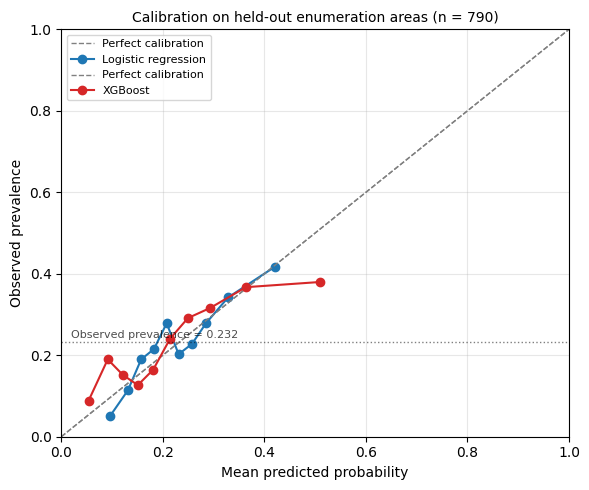


Saved:
  C:\Users\Lenovo\clinical-readmission-risk\results\figures\calibration_test_set.png
  C:\Users\Lenovo\clinical-readmission-risk\results\figures\calibration_test_set.pdf

Binned calibration (Logistic, 10 quantile bins):
  pred = 0.096  observed = 0.051  gap = -0.045
  pred = 0.131  observed = 0.114  gap = -0.017
  pred = 0.157  observed = 0.190  gap = +0.033
  pred = 0.183  observed = 0.215  gap = +0.033
  pred = 0.208  observed = 0.278  gap = +0.071
  pred = 0.231  observed = 0.203  gap = -0.029
  pred = 0.258  observed = 0.228  gap = -0.030
  pred = 0.285  observed = 0.278  gap = -0.007
  pred = 0.328  observed = 0.342  gap = +0.013
  pred = 0.421  observed = 0.418  gap = -0.004


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

# ---------- 1. Write src/evaluate.py (reusable module) ----------
src = Path.home() / "clinical-readmission-risk" / "src"
src.mkdir(parents=True, exist_ok=True)

evaluate_module = '''"""Calibration utilities for the BDHS-2022 stunting risk model.

All public functions accept 1-D arrays of predicted probabilities.
Hard labels are never accepted for AUROC or ECE.
"""
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss


def brier(y_true, y_prob):
    return brier_score_loss(np.asarray(y_true), np.asarray(y_prob))


def expected_calibration_error(y_true, y_prob, n_bins=10, strategy="quantile"):
    """Weighted mean |predicted - observed| across bins.

    strategy='quantile' is default because predicted probabilities from
    imbalanced classifiers are skewed; equal-width bins would place most
    predictions in the first bin and hide miscalibration.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.asarray(y_prob, dtype=float)
    if strategy == "quantile":
        edges = np.quantile(y_prob, np.linspace(0, 1, n_bins + 1))
        edges[0], edges[-1] = -np.inf, np.inf
    else:
        edges = np.linspace(0, 1, n_bins + 1)
    bin_idx = np.digitize(y_prob, edges[1:-1])
    n = len(y_prob)
    ece = 0.0
    for b in range(n_bins):
        mask = bin_idx == b
        if not mask.any():
            continue
        ece += (mask.sum() / n) * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def plot_reliability(y_true, y_prob, ax=None, label=None, n_bins=10, color=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    frac_pos, mean_pred = calibration_curve(
        np.asarray(y_true), np.asarray(y_prob), n_bins=n_bins, strategy="quantile"
    )
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1, label="Perfect calibration")
    ax.plot(mean_pred, frac_pos, marker="o", linewidth=1.5, label=label, color=color)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed prevalence")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    if label:
        ax.legend(fontsize=8, loc="upper left")
    return ax


def bootstrap_brier_ci(y_true, y_prob, n_boot=1000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    n = len(y_true)
    scores = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        scores[i] = brier_score_loss(y_true[idx], y_prob[idx])
    lo, hi = np.quantile(scores, [alpha / 2, 1 - alpha / 2])
    return float(scores.mean()), float(lo), float(hi)
'''
(src / "evaluate.py").write_text(evaluate_module, encoding="utf-8")
print(f"Wrote {src / 'evaluate.py'}")

sys.path.insert(0, str(src))
from evaluate import brier, expected_calibration_error, plot_reliability, bootstrap_brier_ci

# ---------- 2. Load test predictions ----------
processed = Path.home() / "clinical-readmission-risk" / "data" / "processed"
preds = np.load(processed / "test_predictions.npz")
y_test    = preds["y_test"]
p_logit   = preds["p_logit"]
p_xgb     = preds["p_xgb"]

print(f"\nTest set: n = {len(y_test)}, prevalence = {y_test.mean():.3f}")

# ---------- 3. Calibration table ----------
print("\n" + "=" * 62)
print(f"{'Model':<12} {'AUROC':>8} {'Brier':>10} {'Brier 95% CI':>18} {'ECE':>8}")
print("-" * 62)

for name, p in [("Logistic", p_logit), ("XGBoost", p_xgb)]:
    m, lo, hi = bootstrap_brier_ci(y_test, p)
    ece = expected_calibration_error(y_test, p, n_bins=10)
    from sklearn.metrics import roc_auc_score
    auroc = roc_auc_score(y_test, p)
    print(f"{name:<12} {auroc:>8.4f} {m:>10.4f} [{lo:.4f}, {hi:.4f}] {ece:>8.4f}")

# ---------- 4. Reliability diagram (README hero figure) ----------
results = Path.home() / "clinical-readmission-risk" / "results"
(results / "figures").mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
plot_reliability(y_test, p_logit, ax=ax, label="Logistic regression", color="#1f77b4")
plot_reliability(y_test, p_xgb,   ax=ax, label="XGBoost",            color="#d62728")

# Annotate the test prevalence as a horizontal reference for the base rate
ax.axhline(y_test.mean(), linestyle=":", color="black", linewidth=1, alpha=0.5)
ax.text(0.02, y_test.mean() + 0.01, f"Observed prevalence = {y_test.mean():.3f}",
        fontsize=8, color="black", alpha=0.7)

ax.set_title(f"Calibration on held-out enumeration areas (n = {len(y_test)})", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

out_png = results / "figures" / "calibration_test_set.png"
out_pdf = results / "figures" / "calibration_test_set.pdf"
fig.savefig(out_png, dpi=200, bbox_inches="tight")
fig.savefig(out_pdf, bbox_inches="tight")
plt.show()
print(f"\nSaved:\n  {out_png}\n  {out_pdf}")

# ---------- 5. Binned calibration table (for the appendix) ----------
from sklearn.calibration import calibration_curve
print("\nBinned calibration (Logistic, 10 quantile bins):")
frac_pos, mean_pred = calibration_curve(y_test, p_logit, n_bins=10, strategy="quantile")
for mp, fp in zip(mean_pred, frac_pos):
    print(f"  pred = {mp:.3f}  observed = {fp:.3f}  gap = {fp - mp:+.3f}")

In [16]:
import subprocess
from pathlib import Path

project = Path.home() / "clinical-readmission-risk"
r = subprocess.run(["git", "status", "--short"], capture_output=True, text=True, cwd=project)
print(r.stdout or "(working tree clean)")

?? ../.asreview/
?? ../.bash_history
?? ../.conda/
?? ../.gitconfig
?? ../.idlerc/
?? ../.ipynb_checkpoints/
?? ../.ipython/
?? ../.jupyter/
?? ../.keras/
?? ../.lesshst
?? ../.matplotlib/
?? ../.mgltools/
?? ../.openjfx/
?? ../.pymol/
?? ../.pymoltimestamp
?? ../.python_history
?? ../.qiskit/
?? ../.streamlit/
?? ../.vscode/
?? ../00_setup_and_intake.ipynb
?? ../100
?? ../130
?? ../150
?? ../18
?? ../3
?? ../35
?? ../50
?? ../60)
?? ../60).sum())
?? ../85
?? ../88
?? ../AppData/
?? ../Contacts/
?? ../Documents/
?? ../Downloads/
?? ../F1
?? ../Favorites/
?? ../Figure_5.png
?? ../Links/
?? ../Music/
?? "../My Documents/"
?? ../NTUSER.DAT
?? ../NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TM.blf
?? ../NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000001.regtrans-ms
?? ../NTUSER.DAT{2ad838bc-efea-11ee-a54d-000d3a94eaa1}.TMContainer00000000000000000002.regtrans-ms
?? ../OmicsBoxFiles/
?? ../OneDrive/
?? ../PCOS_NHANES_Project/
?? ../PyRx_AutoDock4.tar.gz
?? 

In [17]:
for cmd in [
    ["git", "add", "src/evaluate.py"],
    ["git", "add", "results/figures/calibration_test_set.png"],
    ["git", "add", "results/figures/calibration_test_set.pdf"],
    ["git", "add", "*.ipynb"],
    ["git", "commit", "-m",
     "Add evaluation module and calibration of baseline logistic and XGBoost models on grouped split"],
]:
    r = subprocess.run(cmd, capture_output=True, text=True, cwd=project)
    print(f"$ {' '.join(cmd[:2])}")
    print(r.stdout.strip() or r.stderr.strip())

$ git add

$ git add

$ git add

$ git add
fatal: pathspec '*.ipynb' did not match any files
$ git commit
[main (root-commit) 574d82a] Add evaluation module and calibration of baseline logistic and XGBoost models on grouped split
 3 files changed, 70 insertions(+)
 create mode 100644 clinical-readmission-risk/results/figures/calibration_test_set.pdf
 create mode 100644 clinical-readmission-risk/results/figures/calibration_test_set.png
 create mode 100644 clinical-readmission-risk/src/evaluate.py
